# Laboratoire Monte Carlo : visite guidée

Chaque thème suit le même fil : **intuition -> formule -> ce qu'on attend -> code (appel du package `mclab`) -> lecture du résultat**.
Règle d'or du labo : *aucun prix Monte Carlo sans erreur-type ni IC95, et aucun prix sans référence contre laquelle on le valide.*

Plan : 1. l'estimateur MC et son erreur-type - 2. modèles (Heston, Merton) - 3. réduction de variance - 4. quasi-Monte Carlo - 5. barrière discrète - 6. put américain (Longstaff-Schwartz) - 7. grecques - 8. MLMC - 9. numba - 10. les IC95 sont-ils honnêtes ?

In [1]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # le notebook vit dans notebooks/ ; le package est à la racine

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mclab.analytique import (bs_prix, bs_grecques, heston_prix, merton_prix, asiatique_geo_prix,
                              down_and_out_call, crr_americain)
from mclab.utils import ParamsHeston, ParamsMerton, vol_implicite_bs, payoff_actualise, resumer
from mclab import reduction_variance as rv, qmc, barriere, americaine, grecques, mlmc, accel, validation
from mclab.modeles import gbm_exact, heston_euler, heston_qe, merton_exact

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
S0, K, T, r, sigma = 100.0, 100.0, 1.0, 0.02, 0.2
BS = dict(S0=S0, K=K, T=T, r=r, sigma=sigma)

def lire(nom, res, ref):
    """Une ligne de lecture standard : estimation +/- SE, IC95, référence, z-score."""
    print(f"{nom:<34} {res.prix:9.4f} +/- {res.erreur_type:.4f}   IC95 [{res.ic_bas:.4f} ; {res.ic_haut:.4f}]   "
          f"ref {ref:.4f}   z = {res.z(ref):+.2f}   {'compatible' if abs(res.z(ref)) < 3 else 'INCOMPATIBLE'}")

## 1. L'estimateur Monte Carlo et son erreur-type

**Intuition.** Le prix d'une option est une espérance : $C = e^{-rT}\,\mathbb{E}[(S_T-K)^+]$. On simule $n$ valeurs de $S_T$, on calcule le payoff actualisé de chacune, et on prend la moyenne.

**Formule.** Pour $n$ payoffs indépendants $Y_i$ :
$$\hat C = \frac1n\sum_i Y_i,\qquad \mathrm{SE} = \frac{s}{\sqrt n},\qquad \text{IC95} = \hat C \pm 1{,}96\,\mathrm{SE}$$
où $s$ est l'écart-type empirique des $Y_i$. Le **z-score** $z=(\hat C - C_{\text{ref}})/\mathrm{SE}$ mesure l'écart à la référence en erreurs-types.

**Ce qu'on attend.** $|z|<3$ presque toujours (un $|z|>3$ signale un bug) et une erreur-type qui est **divisée par 2 quand on multiplie $n$ par 4**.

In [2]:
ref = bs_prix(**BS)
print(f"Black-Scholes (formule fermée) : {ref:.4f}\n")
anciens = None
for n in (1_000, 10_000, 100_000, 1_000_000):
    res = rv.mc_naif("call_europeen", n_pas=1, n_chemins=n, graine=1, **BS)
    lire(f"MC naïf, n = {n:>9,}".replace(",", " "), res, ref)
    if anciens: print(f"{'':<34} SE précédente / SE actuelle = {anciens / res.erreur_type:.2f}  (attendu ~ sqrt(10) = 3.16)")
    anciens = res.erreur_type

Black-Scholes (formule fermée) : 8.9160

MC naïf  n =     1 000                8.1129 +/- 0.4175   IC95 [7.2945 ; 8.9313]   ref 8.9160   z = -1.92   compatible
MC naïf  n =    10 000                8.7821 +/- 0.1368   IC95 [8.5140 ; 9.0501]   ref 8.9160   z = -0.98   compatible
                                   SE précédente / SE actuelle = 3.05  (attendu ~ sqrt(10) = 3.16)
MC naïf  n =   100 000                8.8286 +/- 0.0435   IC95 [8.7434 ; 8.9139]   ref 8.9160   z = -2.01   compatible
                                   SE précédente / SE actuelle = 3.14  (attendu ~ sqrt(10) = 3.16)
MC naïf  n = 1 000 000                8.8917 +/- 0.0138   IC95 [8.8647 ; 8.9187]   ref 8.9160   z = -1.77   compatible
                                   SE précédente / SE actuelle = 3.16  (attendu ~ sqrt(10) = 3.16)


**Lecture.** Les cinq estimations sont compatibles avec la formule fermée, et chaque facteur 10 sur $n$ divise l'erreur-type par environ $\sqrt{10}$. Un prix MC *sans* son erreur-type ne dit rien : on ne saurait pas distinguer un bon résultat d'un bug.

## 2. Les modèles : Heston (Euler vs QE) et Merton

**Intuition.** Black-Scholes suppose une volatilité constante. Heston la rend aléatoire (elle revient vers une moyenne et corrèle négativement avec le prix, ce qui crée le *smile*) ; Merton ajoute des sauts.

**Formules (Heston).** $dS=(r-q)S\,dt+\sqrt v\,S\,dW^1$, $\;dv=\kappa(\theta-v)dt+\xi\sqrt v\,dW^2$, $\;d\langle W^1,W^2\rangle=\rho\,dt$.
Paramètres de référence : $v_0=\theta=0{,}04,\ \kappa=1{,}5,\ \xi=0{,}5,\ \rho=-0{,}7$. La condition de Feller $2\kappa\theta\ge\xi^2$ est **violée** ici ($0{,}12<0{,}25$) : la variance touche zéro, c'est le cas difficile pour les schémas naïfs.

- *Euler full-truncation* : on remplace $v$ par $\max(v,0)$ partout. Simple, mais biaisé en $O(dt)$.
- *QE (Andersen 2008)* : on approche la vraie loi de $v_{t+dt}\mid v_t$ (khi-deux non centrée) par une forme quadratique ou exponentielle selon la valeur de $\psi=s^2/m^2$ : précis même avec très peu de pas.
- *Référence* : prix semi-fermé par inversion de la fonction caractéristique (formulation « little trap »).

**Ce qu'on attend.** QE à 10 pas $\approx$ référence ; Euler à 10 pas visiblement biaisé, le biais fondant avec le nombre de pas.

In [3]:
H = ParamsHeston()
ref_h = heston_prix(H, K, T)
print(f"Heston semi-fermé : {ref_h:.4f}   (Black-Scholes à 20 % : {bs_prix(**BS):.4f})\n")

def prix_depuis(S, r_):
    return resumer(payoff_actualise("call_europeen", S, K, r_, T), time.perf_counter())

for nom, S in (("Euler, 10 pas", heston_euler(H, T, 10, 200_000, graine=2)),
               ("Euler, 100 pas", heston_euler(H, T, 100, 200_000, graine=2)),
               ("QE, 10 pas", heston_qe(H, T, 10, 200_000, graine=2))):
    lire(nom, prix_depuis(S, H.r), ref_h)

M = ParamsMerton()
lire("Merton exact (10 pas)", prix_depuis(merton_exact(M, T, 10, 200_000, graine=3), M.r), merton_prix(M, K, T))

Heston semi-fermé : 8.1950   (Black-Scholes à 20 % : 8.9160)



Euler, 10 pas                         8.3666 +/- 0.0225   IC95 [8.3225 ; 8.4107]   ref 8.1950   z = +7.63   INCOMPATIBLE
Euler, 100 pas                        8.2357 +/- 0.0218   IC95 [8.1931 ; 8.2784]   ref 8.1950   z = +1.87   compatible
QE, 10 pas                            8.2159 +/- 0.0218   IC95 [8.1732 ; 8.2585]   ref 8.1950   z = +0.96   compatible
Merton exact (10 pas)                10.0686 +/- 0.0349   IC95 [10.0003 ; 10.1370]   ref 10.1272   z = -1.68   compatible


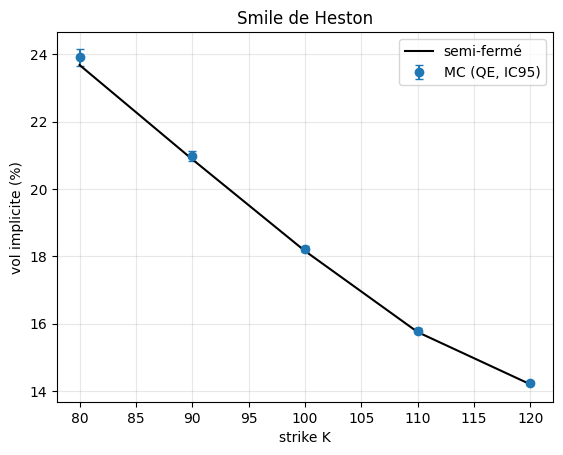

In [4]:
# Le smile : vol implicite du prix MC (QE) contre la vol implicite du prix semi-fermé
strikes = np.array([80, 90, 100, 110, 120])
S = heston_qe(H, T, 20, 300_000, graine=4)
iv_mc, iv_ex, demi = [], [], []
for k in strikes:
    res = resumer(payoff_actualise("call_europeen", S, float(k), H.r, T), time.perf_counter())
    iv_mc.append(vol_implicite_bs(res.prix, H.S0, k, T, H.r))
    iv_ex.append(vol_implicite_bs(heston_prix(H, k, T), H.S0, k, T, H.r))
    bas = vol_implicite_bs(res.prix - 1.96 * res.erreur_type, H.S0, k, T, H.r)
    haut = vol_implicite_bs(res.prix + 1.96 * res.erreur_type, H.S0, k, T, H.r)
    demi.append((haut - bas) / 2)
plt.errorbar(strikes, 100 * np.array(iv_mc), yerr=100 * np.array(demi), fmt="o", capsize=3, label="MC (QE, IC95)")
plt.plot(strikes, 100 * np.array(iv_ex), "-k", label="semi-fermé")
plt.xlabel("strike K"); plt.ylabel("vol implicite (%)"); plt.legend(); plt.title("Smile de Heston")
plt.show()

**Lecture.** QE retrouve le prix de référence avec 10 pas seulement ; Euler en demande dix fois plus pour s'en approcher (le biais se lit directement dans la colonne z). Le smile MC suit la courbe semi-fermée à l'intérieur des barres d'erreur : la corrélation négative $\rho$ donne bien une vol implicite plus haute pour les petits strikes.

## 3. Réduction de variance

**Intuition.** Pour une précision donnée, la variance détermine le nombre de chemins nécessaires. On peut la réduire *sans biais* en exploitant de l'information connue. L'indicateur honnête est le **facteur d'efficacité** $\dfrac{\mathrm{var}_{\text{naïf}}\cdot t_{\text{naïf}}}{\mathrm{var}_{\text{VR}}\cdot t_{\text{VR}}}$ : il tient compte du temps de calcul supplémentaire.

**Trois techniques.**
1. *Antithétique* : on simule $Z$ et $-Z$ ; les deux payoffs sont corrélés négativement, leur moyenne varie moins.
2. *Variable de contrôle* : on estime $\mathbb E[Y-\beta(X-\mathbb E X)]$ où $X$ est corrélée à $Y$ et d'espérance connue. Pour l'asiatique arithmétique, $X$ = asiatique géométrique (formule fermée). $\beta=\mathrm{Cov}(Y,X)/\mathrm{Var}(X)$ est estimé sur un échantillon pilote **indépendant** (sinon léger biais).
3. *Importance sampling* : pour un call très hors de la monnaie, on tire $Z\sim\mathcal N(\mu,1)$ avec $\mu$ centré sur le strike, et on corrige par le poids $e^{-\mu Z-\mu^2/2}$.

**Ce qu'on attend.** Antithétique $\approx 2\times$ ; contrôle géométrique sur l'asiatique $\gg 10\times$ ; importance sampling $\gg 10\times$ sur le call OTM.

In [5]:
n = 200_000
ref_eur = bs_prix(**BS)
naif = rv.mc_naif("call_europeen", n_pas=1, n_chemins=n, graine=5, **BS)
anti = rv.mc_antithetique("call_europeen", n_pas=1, n_chemins=n, graine=5, **BS)
lire("Européen, naïf", naif, ref_eur); lire("Européen, antithétique", anti, ref_eur)
print(f"   -> facteur de variance {rv.facteur_variance(naif, anti):.2f}, d'efficacité {rv.facteur_efficacite(naif, anti):.2f}\n")

# Asiatique arithmétique : pas de formule fermée -> référence = MC haute précision avec contrôle (indépendant)
lots = [rv.mc_controle("call_asiatique_arith", n_pas=12, n_chemins=200_000, graine=900 + i, **BS) for i in range(5)]
ref_asia = np.mean([l.prix for l in lots]); se_ref = np.sqrt(sum(l.erreur_type**2 for l in lots)) / len(lots)
print(f"Référence asiatique arithmétique (1 M chemins avec contrôle) : {ref_asia:.4f} +/- {se_ref:.4f}")
a_naif = rv.mc_naif("call_asiatique_arith", n_pas=12, n_chemins=n, graine=6, **BS)
a_ctrl = rv.mc_controle("call_asiatique_arith", n_pas=12, n_chemins=n, graine=6, **BS)
lire("Asiatique arith., naïf", a_naif, ref_asia); lire("Asiatique arith., contrôle géométrique", a_ctrl, ref_asia)
print(f"   -> facteur de variance {rv.facteur_variance(a_naif, a_ctrl):.0f}, d'efficacité {rv.facteur_efficacite(a_naif, a_ctrl):.0f}\n")

# Call très hors de la monnaie
OTM = dict(S0=S0, K=180.0, T=T, r=r, sigma=sigma)
ref_otm = bs_prix(**OTM)
o_naif = rv.mc_naif("call_europeen", n_pas=1, n_chemins=n, graine=7, **OTM)
o_is = rv.mc_importance_call(n_chemins=n, graine=7, **OTM)
print(f"Call K=180 : valeur exacte {ref_otm:.5f}, translation mu = {rv.mu_optimal_call(**OTM):.2f}")
lire("Call OTM, naïf", o_naif, ref_otm); lire("Call OTM, importance sampling", o_is, ref_otm)
print(f"   -> facteur de variance {rv.facteur_variance(o_naif, o_is):.0f}, d'efficacité {rv.facteur_efficacite(o_naif, o_is):.0f}")

Européen, naïf                        8.9527 +/- 0.0310   IC95 [8.8920 ; 9.0134]   ref 8.9160   z = +1.18   compatible
Européen, antithétique                8.8992 +/- 0.0235   IC95 [8.8531 ; 8.9453]   ref 8.9160   z = -0.72   compatible
   -> facteur de variance 1.73, d'efficacité 1.40



Référence asiatique arithmétique (1 M chemins avec contrôle) : 5.3781 +/- 0.0002
Asiatique arith., naïf                5.3984 +/- 0.0181   IC95 [5.3629 ; 5.4339]   ref 5.3781   z = +1.12   compatible
Asiatique arith., contrôle géométrique    5.3778 +/- 0.0005   IC95 [5.3768 ; 5.3787]   ref 5.3781   z = -0.66   compatible
   -> facteur de variance 1405, d'efficacité 958

Call K=180 : valeur exacte 0.01765, translation mu = 2.94
Call OTM, naïf                        0.0168 +/- 0.0013   IC95 [0.0143 ; 0.0193]   ref 0.0177   z = -0.65   compatible
Call OTM, importance sampling         0.0176 +/- 0.0001   IC95 [0.0175 ; 0.0177]   ref 0.0177   z = -0.27   compatible
   -> facteur de variance 642, d'efficacité 819


**Lecture.** L'antithétique gagne un facteur ~1,7 sur un call (modeste, comme prévu). Le contrôle géométrique est spectaculaire sur l'asiatique : l'asiatique arithmétique et la géométrique sont quasi identiques, donc la différence $Y-X$ est presque constante. L'importance sampling fait passer l'erreur relative du call OTM d'environ 7 % à moins de 1 % pour le même nombre de chemins. Dans tous les cas, **les estimations restent compatibles avec la référence** : on a gagné en précision sans introduire de biais.

## 4. Quasi-Monte Carlo : Sobol brouillé et pont brownien

**Intuition.** Des points pseudo-aléatoires laissent des trous et des amas ; une suite à faible discrépance (Sobol) remplit l'espace régulièrement. L'erreur passe de $\sim N^{-1/2}$ à $\sim N^{-1}$ (à des logarithmes près) pour les intégrandes assez réguliers.

**Deux ingrédients.**
- *Randomisation* : une suite de Sobol déterministe n'a pas d'erreur-type. On la **brouille** $K$ fois indépendamment : les $K$ estimations sont i.i.d. et non biaisées, leur dispersion donne une erreur-type honnête (IC de Student, $K-1$ degrés de liberté).
- *Pont brownien* : on construit le chemin en commençant par la valeur finale $W_T$, puis le milieu, puis les quarts... Les premières coordonnées du point Sobol (les mieux réparties) portent ainsi l'essentiel de la variance du chemin ; l'effet est fort sur les payoffs dépendant du chemin.

**Ce qu'on attend.** Pente log-log de la RMSE $\approx -0{,}5$ pour MC, nettement plus raide pour QMC (au mieux proche de $-1$), avec le pont meilleur que l'ordre naïf des incréments.

Asiatique géo., QMC pont 16 x 2^12    5.1093 +/- 0.0008   IC95 [5.1076 ; 5.1111]   ref 5.1089   z = +0.56   compatible
Asiatique géo.  MC même N (65 536)    5.1133 +/- 0.0300   IC95 [5.0544 ; 5.1721]   ref 5.1089   z = +0.15   compatible
-> erreur-type MC / QMC = 37



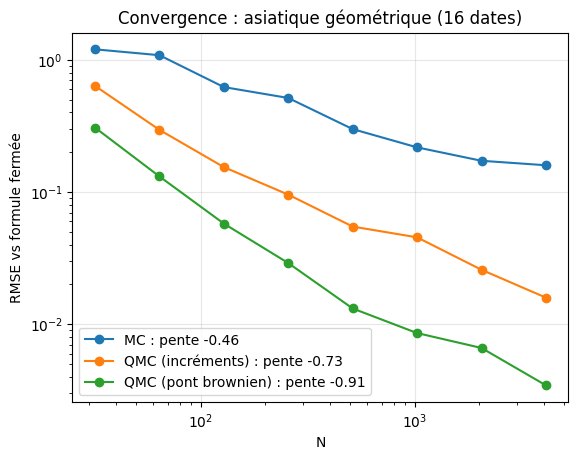

In [6]:
ref_geo = asiatique_geo_prix(S0, K, T, r, sigma, 16)
res = qmc.prix_gbm_qmc("call_asiatique_geo", n_pas=16, m=12, k_brouillages=16, graine=1, **BS)
lire("Asiatique géo., QMC pont 16 x 2^12", res, ref_geo)
mc = rv.mc_naif("call_asiatique_geo", n_pas=16, n_chemins=res.n_chemins, graine=1, **BS)
lire(f"Asiatique géo., MC même N ({mc.n_chemins:,})".replace(",", " "), mc, ref_geo)
print(f"-> erreur-type MC / QMC = {mc.erreur_type / res.erreur_type:.0f}\n")

etude = qmc.etude_convergence(ms=range(5, 13), repetitions=25, graine=0)
N = etude["N"]
for cle, nom in (("mc", "MC"), ("qmc_incrementale", "QMC (incréments)"), ("qmc_pont", "QMC (pont brownien)")):
    plt.loglog(N, etude["rmse"][cle], "o-", label=f"{nom} : pente {etude['pentes'][cle]:.2f}")
plt.xlabel("N"); plt.ylabel("RMSE vs formule fermée"); plt.legend(); plt.title("Convergence : asiatique géométrique (16 dates)")
plt.show()

**Lecture.** À nombre de chemins égal le QMC randomisé est des dizaines de fois plus précis. Les pentes mesurées sont proches de $-0{,}5$ pour MC et nettement plus raides pour QMC ; le pont brownien est le meilleur des deux ordres de construction. La pente QMC reste un peu au-dessus de $-1$ (le payoff a un coude à $\max(\cdot,0)$), ce qui est la valeur réaliste à retenir.

## 5. Barrière : le piège de la surveillance discrète

**Intuition.** La formule fermée d'un call *down-and-out* suppose que la barrière $H$ est surveillée **en continu**. Une simulation ne regarde que $m$ dates : un chemin peut passer sous $H$ *entre* deux dates et revenir sans être vu, donc le MC naïf **sous-estime** les knock-outs et **sur-estime** le prix.

**Correction par pont brownien.** Sachant $S_i$ et $S_{i+1}$ tous deux au-dessus de $H$, la probabilité que le chemin ait *quand même* touché $H$ entre les deux vaut $\exp\!\big(-2\ln(S_i/H)\ln(S_{i+1}/H)/(\sigma^2\Delta t)\big)$. On pondère chaque chemin par la probabilité de survie correspondante.

**Ce qu'on attend.** Biais naïf positif qui diminue lentement avec $m$ ; correction par pont compatible avec la formule continue dès $m$ petit.

In [7]:
P = dict(S0=100.0, K=100.0, H=90.0, T=1.0, r=0.02, sigma=0.2)
ref_b = down_and_out_call(**P)
print(f"Formule continue (Reiner-Rubinstein) : {ref_b:.4f}\n")
for m in (10, 50):
    for methode in ("naif", "bgk", "pont"):
        lire(f"m = {m:>3}, {methode}", barriere.down_and_out_mc(m=m, n_chemins=200_000, graine=8, methode=methode, **P), ref_b)
    print()

Formule continue (Reiner-Rubinstein) : 7.3004

m =  10, naif                         8.1024 +/- 0.0307   IC95 [8.0423 ; 8.1625]   ref 7.3004   z = +26.16   INCOMPATIBLE
m =  10, bgk                          7.2591 +/- 0.0302   IC95 [7.2000 ; 7.3182]   ref 7.3004   z = -1.37   compatible


m =  10, pont                         7.2448 +/- 0.0295   IC95 [7.1869 ; 7.3027]   ref 7.3004   z = -1.88   compatible



m =  50, naif                         7.7039 +/- 0.0305   IC95 [7.6442 ; 7.7636]   ref 7.3004   z = +13.24   INCOMPATIBLE


m =  50, bgk                          7.2472 +/- 0.0302   IC95 [7.1881 ; 7.3063]   ref 7.3004   z = -1.77   compatible


m =  50, pont                         7.2450 +/- 0.0299   IC95 [7.1863 ; 7.3036]   ref 7.3004   z = -1.86   compatible



**Lecture.** Le MC naïf est franchement hors tolérance (z de plusieurs dizaines) et son biais décroît lentement avec $m$ ; avec le pont brownien (ou le décalage de Broadie-Glasserman-Kou) on retombe sur la formule continue même avec 10 dates. C'est un biais *de modélisation*, invisible à l'erreur-type : seul le test contre une référence l'expose.

## 6. Put américain : Longstaff-Schwartz

**Intuition.** À chaque date on compare le gain immédiat $(K-S)^+$ à la valeur de **continuation** (ce qu'on obtiendrait en gardant l'option), qu'on ne connaît pas. LSM l'estime par **régression** sur les chemins dans la monnaie, avec les polynômes de Laguerre de $S/K$ (degré 3).

**Piège central.** Si l'on évalue la règle d'exercice sur les *mêmes* chemins que ceux qui l'ont apprise, la règle « connaît l'avenir » de ces chemins : biais haut (biais de prévoyance). Ici : **jeu d'apprentissage** pour la règle, **jeu indépendant** pour le prix. La règle étant sous-optimale, l'estimateur est **biaisé bas**.

**Encadrement.** Une **borne haute** vient de la dualité (Rogers 2002, Haugh-Kogan 2004) : pour toute martingale $M$, $V_0\le\mathbb E[\max_j (D_j G_j - M_j)]$. On construit $M$ avec la fonction de valeur approchée issue de la régression.

**Ce qu'on attend.** borne basse $\le$ prix de l'arbre binomial (mêmes dates d'exercice) $\le$ borne haute.

Put européen (BS)              : 5.1660
Put américain CRR (N=2000)     : 5.7986
CRR bermudéen (10 dates)        : 5.7318   <- référence exacte pour ces dates d'exercice
LSM sur l'apprentissage        : 5.7213   (mêmes chemins que la règle : biais de prévoyance)
LSM hors échantillon (bas)            5.7243 +/- 0.0137   IC95 [5.6974 ; 5.7512]   ref 5.7318   z = -0.55   compatible
Borne haute duale              : 5.7668 +/- 0.0038

encadrement respecté : True


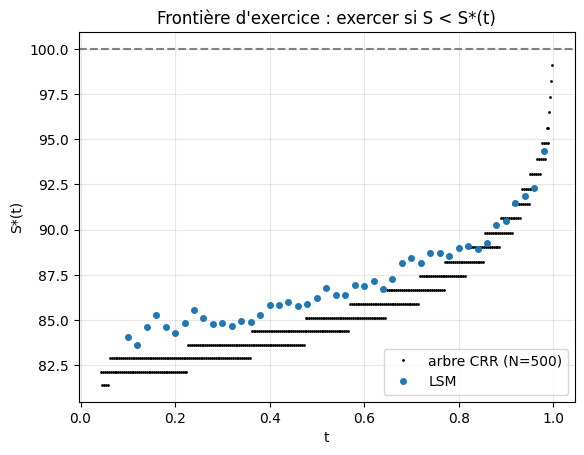

In [8]:
PA = dict(S0=100.0, K=100.0, T=1.0, r=0.06, sigma=0.2)
n_dates = 10
lsm = americaine.lsm_put_americain(**PA, n_pas=n_dates, n_apprentissage=50_000, n_evaluation=100_000, graine=0)
haute = americaine.borne_haute_duale(lsm, n_exterieurs=3000)
ber = crr_americain(**PA, N=2000, pas_exercice=2000 // n_dates)
print(f"Put européen (BS)              : {bs_prix(**PA, type_option='put'):.4f}")
print(f"Put américain CRR (N=2000)     : {crr_americain(**PA, N=2000):.4f}")
print(f"CRR bermudéen ({n_dates} dates)        : {ber:.4f}   <- référence exacte pour ces dates d'exercice")
print(f"LSM sur l'apprentissage        : {lsm.prix_apprentissage:.4f}   (mêmes chemins que la règle : biais de prévoyance)")
lire("LSM hors échantillon (bas)", lsm.resultat, ber)
print(f"Borne haute duale              : {haute.prix:.4f} +/- {haute.erreur_type:.4f}")
print(f"\nencadrement respecté : {lsm.resultat.prix - 3*lsm.resultat.erreur_type <= ber <= haute.prix + 3*haute.erreur_type}")

# frontière d'exercice (50 dates) contre l'arbre
lsm50 = americaine.lsm_put_americain(**PA, n_pas=50, n_apprentissage=50_000, n_evaluation=20_000, graine=1)
_, front = crr_americain(**PA, N=500, retourner_frontiere=True)
plt.plot(np.arange(500) / 500, front[:500], "k.", ms=2, label="arbre CRR (N=500)")
plt.plot(lsm50.dates[1:-1], lsm50.frontiere[1:], "o", ms=4, label="LSM")
plt.axhline(PA["K"], ls="--", color="gray"); plt.xlabel("t"); plt.ylabel("S*(t)"); plt.legend()
plt.title("Frontière d'exercice : exercer si S < S*(t)"); plt.show()

**Lecture.** Le prix LSM hors échantillon est un peu *sous* l'arbre et la borne haute un peu *au-dessus* : le vrai prix est coincé entre les deux (écart de l'ordre de 0,5 % à 10 dates). La borne haute se desserre quand on ajoute des dates (valeur approchée moins précise) : c'est une limite connue, documentée dans le README. La frontière LSM suit celle de l'arbre, avec du bruit aux dates précoces où très peu de chemins sont exercés.

## 7. Les grecques : pathwise, rapport de vraisemblance, bump

**Intuition.** On veut $\partial_\theta\,\mathbb E[f(S_T)]$. Trois façons :
- **Pathwise** : on dérive le payoff le long du chemin, $\mathbb E[f'(S_T)\,\partial_\theta S_T]$. Faible variance mais exige un payoff dérivable.
- **Rapport de vraisemblance (LR)** : on dérive la densité, $\mathbb E[f(S_T)\,\partial_\theta\ln p_\theta(S_T)]$. Marche pour *tout* payoff, variance plus élevée.
- **Bump-and-revalue** : différence finie avec les **mêmes** nombres aléatoires (CRN) pour que le bruit se compense.

**Cas test décisif : la digitale** ($\mathbf 1_{S_T>K}$). Sa dérivée est nulle presque partout : le pathwise renvoie 0 (faux), alors que LR et bump marchent.

**Ce qu'on attend.** Tout à moins de 3 erreurs-types de la valeur exacte, **sauf** pathwise sur la digitale.

In [9]:
rows = []
for (payoff, grecque, methode), (res, exacte) in grecques.toutes_les_grecques(n_chemins=300_000, graine=3).items():
    rows.append(dict(payoff=payoff, grecque=grecque, methode=methode, estimation=res.prix, SE=res.erreur_type,
                     exacte=exacte, z=res.z(exacte)))
pd.DataFrame(rows).round(5)

,payoff,grecque,methode,estimation,SE,exacte,z
0,call,delta,pathwise,0.57962,0.00108,0.57926,0.33437
1,call,delta,lr,0.58016,0.00253,0.57926,0.35589
2,call,delta,bump,0.57953,0.00107,0.57926,0.25324
3,call,gamma,lr,0.01951,0.00024,0.01955,-0.16140
4,call,gamma,bump,0.01941,0.00020,0.01955,-0.70863
5,call,vega,pathwise,39.16657,0.13615,39.10427,0.45759
6,call,vega,lr,39.02815,0.47161,39.10427,-0.16140
7,call,vega,bump,39.16561,0.13614,39.10427,0.45054
8,digitale,delta,pathwise,0.00000,0.00000,0.01955,inf
9,digitale,delta,lr,0.01958,0.00005,0.01955,0.49250


**Lecture.** Pour le call, pathwise et bump (CRN) sont les plus précis (SE 2 à 3 fois plus petite que LR sur le delta) ; LR est le seul à donner le gamma sans différence seconde bruyante. Sur la digitale, la ligne `pathwise` affiche 0 avec une erreur-type nulle : l'estimateur est *confiant et faux* (z infini). LR et bump restent corrects, le bump avec une variance en $1/h$ : c'est la raison d'être de LR.

## 8. Multilevel Monte Carlo (Giles)

**Intuition.** Avec Euler, plus le pas est fin, moins le biais est grand mais plus le chemin coûte. MLMC décompose
$$\mathbb E[P_L]=\mathbb E[P_0]+\sum_{l=1}^{L}\mathbb E[P_l-P_{l-1}]$$
et simule chaque différence avec **les mêmes incréments browniens** pour le chemin fin et le chemin grossier : $V_l=\mathrm{Var}[P_l-P_{l-1}]$ décroît avec le niveau. Les niveaux grossiers (bon marché, grande variance) reçoivent beaucoup de chemins, les niveaux fins (chers, petite variance) très peu : $n_l\propto\sqrt{V_l/C_l}$.

**Ce qu'on attend.** $V_l\sim 2^{-l}$ (Euler), $\mathbb E[P_l-P_{l-1}]$ décroissant, et un coût $\sim\varepsilon^{-2}$ au lieu de $\sim\varepsilon^{-3}$ pour le MC standard.

In [10]:
ref = bs_prix(**BS)
ech = mlmc.echantillonneur_gbm_euler(S0, K, T, r, sigma)
res = mlmc.mlmc(ech, 0.01, graine=1)
lire("MLMC GBM, eps = 0.01", res.resultat, ref)
print(f"niveaux 0..{res.niveaux[-1]} ; coût MLMC {res.cout:.2e} pas-chemins ; coût MC standard estimé {res.cout_mc_standard:.2e}\n")
pd.DataFrame({"niveau": res.niveaux, "E[P_l - P_(l-1)]": res.moy_Y, "Var[P_l - P_(l-1)]": res.var_Y,
              "Var[P_l]": res.var_P, "n_l": res.n_l.astype(int)}).round(5)

MLMC GBM, eps = 0.01                  8.9191 +/- 0.0071   IC95 [8.9052 ; 8.9329]   ref 8.9160   z = +0.43   compatible
niveaux 0..4 ; coût MLMC 8.56e+06 pas-chemins ; coût MC standard estimé 6.02e+07



,niveau,E[P_l - P_(l-1)],Var[P_l - P_(l-1)],Var[P_l],n_l
0,0,8.84595,146.67009,146.67009,5010466
1,1,0.07151,2.03120,167.16310,417003
2,2,0.00871,1.11466,177.87749,218141
3,3,-0.00259,0.60170,184.59714,113496
4,4,-0.00453,0.31774,188.21642,58336


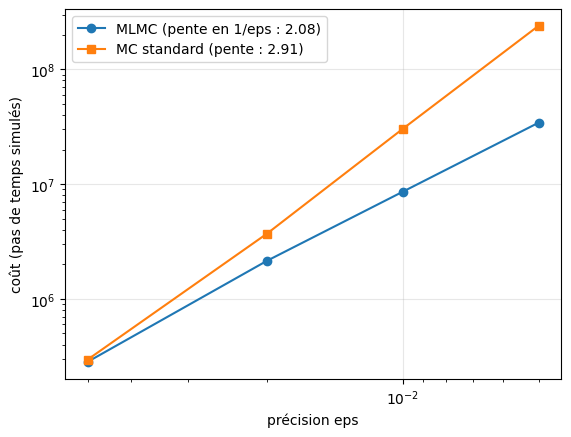

In [11]:
eps = [0.05, 0.02, 0.01, 0.005]
runs = mlmc.cout_vs_epsilon(ech, eps, graine=10)
c_ml = np.array([x.cout for x in runs]); c_std = np.array([x.cout_mc_standard for x in runs])
plt.loglog(eps, c_ml, "o-", label=f"MLMC (pente en 1/eps : {np.polyfit(np.log(1/np.array(eps)), np.log(c_ml), 1)[0]:.2f})")
plt.loglog(eps, c_std, "s-", label=f"MC standard (pente : {np.polyfit(np.log(1/np.array(eps)), np.log(c_std), 1)[0]:.2f})")
plt.xlabel("précision eps"); plt.ylabel("coût (pas de temps simulés)"); plt.gca().invert_xaxis(); plt.legend(); plt.show()

**Lecture.** La variance par niveau décroît d'un facteur 2 par niveau comme prévu, le biais $\mathbb E[P_l-P_{l-1}]$ aussi, et les nombres de chemins $n_l$ s'effondrent sur les niveaux fins. La pente du coût en $1/\varepsilon$ est voisine de 2 pour MLMC contre ~3 pour le MC standard. **Limite honnête** : à précision lâche ($\varepsilon\gtrsim 0{,}05$ ici) le MC standard coûte autant ou moins que MLMC ; MLMC gagne dès $\varepsilon\lesssim 0{,}02$. Sur Heston avec Euler full-truncation, $V_l$ décroît plus lentement et le croisement n'apparaît que pour $\varepsilon$ plus petit encore (voir le README).

## 9. Accélération numba

**Intuition.** En numpy, chaque pas de temps balaie un tableau de $n$ chemins en mémoire plusieurs fois (une opération = un balayage). En numba, **un chemin = une boucle sur les pas** : il tient dans les registres du processeur, sans tableau intermédiaire, et les chemins sont répartis sur les coeurs (`prange`). Le noyau utilise un générateur SplitMix64 par chemin : le résultat ne dépend que de la graine, pas du nombre de threads.

**Ce qu'on attend.** Même prix que la version numpy (à l'erreur-type près), et beaucoup plus de chemins par seconde.

In [12]:
res = accel.prix_call_heston_numba(H, K, T, 50, 1_000_000, graine=1)
lire("Heston QE numba (1 M chemins)", res, ref_h)
b = accel.benchmark(H, T, 50, 100_000)
for nom in ("numpy_trajectoires_completes", "numpy_terminal_seul", "numba_parallele"):
    print(f"{nom:<32} {b[nom]['temps_s']:.3f} s   {b[nom]['chemins_par_s']:>12,.0f} chemins/s")
print(f"\naccélération numba / numpy (S_T seul) : x{b['acceleration_vs_numpy_terminal']:.0f}")

Heston QE numba (1 M chemins)         8.1913 +/- 0.0097   IC95 [8.1723 ; 8.2103]   ref 8.1950   z = -0.39   compatible


numpy_trajectoires_completes     0.902 s        110,906 chemins/s
numpy_terminal_seul              0.641 s        156,005 chemins/s
numba_parallele                  0.020 s      4,984,126 chemins/s

accélération numba / numpy (S_T seul) : x32


**Lecture.** Le prix numba est compatible avec la référence semi-fermée, et le gain de vitesse est d'un à deux ordres de grandeur (il dépend du nombre de coeurs de la machine). Comparaison honnête : `numpy_terminal_seul` exécute le même algorithme que numba sans stocker les trajectoires ; `numpy_trajectoires_completes` est ce que renvoie l'API publique `heston_qe`.

## 10. Les barres d'erreur sont-elles honnêtes ? Test de couverture

**Intuition.** Un IC à 95 % ne vaut quelque chose que s'il contient la vraie valeur dans 95 % des cas. On le vérifie : on répète l'estimation avec des graines indépendantes et on compte la fraction d'IC qui contiennent la formule fermée.

**Formule.** Avec $R$ répétitions, la couverture observée a pour écart-type $\sqrt{0{,}95\cdot0{,}05/R}$ ($\approx0{,}7$ point pour $R=1000$) : on tolère 3 écarts-types.

**Ce qu'on attend.** ~95 % pour tous les estimateurs bien construits. **Contre-exemple** : MC naïf sur un événement rare (call très OTM, 2 000 chemins) - la loi normale ne s'applique plus, l'IC sous-couvre.

In [13]:
n = 2000
lignes = {}
for nom, est, ref_ in (
    ("MC naïf", lambda g: rv.mc_naif("call_europeen", n_pas=1, n_chemins=n, graine=g, **BS), bs_prix(**BS)),
    ("antithétique", lambda g: rv.mc_antithetique("call_europeen", n_pas=1, n_chemins=n, graine=g, **BS), bs_prix(**BS)),
    ("contrôle", lambda g: rv.mc_controle("call_europeen", n_pas=1, n_chemins=n, graine=g, n_pilote=5000, **BS), bs_prix(**BS)),
    ("importance (K=180)", lambda g: rv.mc_importance_call(n_chemins=n, graine=g, **OTM), ref_otm),
    ("MC naïf (K=180, rare)", lambda g: rv.mc_naif("call_europeen", n_pas=1, n_chemins=n, graine=g, **OTM), ref_otm)):
    lignes[nom] = validation.couverture_ic95(est, ref_, repetitions=500, graine=0)
for nom, c in lignes.items():
    print(f"{nom:<24} couverture {100 * c['couverture']:5.1f} %   ({c['ecart_en_sigmas']:+.1f} sigmas binomiaux)")

MC naïf                  couverture  94.0 %   (-1.0 sigmas binomiaux)
antithétique             couverture  94.4 %   (-0.6 sigmas binomiaux)
contrôle                 couverture  94.6 %   (-0.4 sigmas binomiaux)
importance (K=180)       couverture  94.6 %   (-0.4 sigmas binomiaux)
MC naïf (K=180, rare)    couverture  76.0 %   (-19.5 sigmas binomiaux)


**Lecture.** Les quatre estimateurs « réguliers » couvrent ~95 % du temps (écarts de l'ordre de 1 sigma) : leurs erreurs-types sont fiables, y compris celle de la variable de contrôle avec son $\beta$ pilote et celle de l'importance sampling. Le MC naïf sur l'événement rare sous-couvre massivement (~75 %) : l'erreur-type affichée est *trop petite* parce que l'échantillon contient très peu de chemins gagnants. L'importance sampling répare à la fois la précision **et** la couverture.

## Pour aller plus loin

- Relancer toute la validation (JSON + figures + tableaux de docs/validation.md) : `python scripts/run_all.py`
- Tests : `python -m pytest -q`
- Limites et pistes (stratification, mini-xVA, GPU) : voir le README.